In [3]:

# Step 3: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

# Load the dataset

df = pd.read_excel("/content/ApexPlanet_DataAnalytics_Dataset.xlsx")

# Display first five rows
df.head()


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [5]:

# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()


Dataset Shape: (1000, 12)

Column Names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Missing Values:
Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              20
Gender            0
City             13
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product     

In [6]:

# Separate sales based on gender

male_sales = df[df["Gender"] == "Male"]["Total_Sales"].dropna()

female_sales = df[df["Gender"] == "Female"]["Total_Sales"].dropna()

print("Male records:", len(male_sales))
print("Female records:", len(female_sales))


Male records: 511
Female records: 489


In [7]:

print("Male Average Sales:", male_sales.mean())

print("Female Average Sales:", female_sales.mean())


Male Average Sales: 141807.3397847358
Female Average Sales: 136883.20862985688


In [8]:

# Welch Independent Samples T-Test

t_stat, p_value = stats.ttest_ind(
    male_sales,
    female_sales,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)


T-statistic: 0.6826103913380815
P-value: 0.4950114785145835


In [9]:

if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("There is a significant difference in average sales.")
else:
    print("Fail to Reject Null Hypothesis")
    print("There is no statistically significant difference in average sales.")


Fail to Reject Null Hypothesis
There is no statistically significant difference in average sales.


In [10]:
 if p_value < 0.05:
    print("Reject Null Hypothesis")
    print("There is a significant difference in average sales.")
else:
    print("Fail to Reject Null Hypothesis")
    print("There is no statistically significant difference in average sales.")


Fail to Reject Null Hypothesis
There is no statistically significant difference in average sales.


In [11]:

# Calculate 95% Confidence Interval

n1 = len(male_sales)
n2 = len(female_sales)

v1 = male_sales.var()
v2 = female_sales.var()

mean_diff = male_sales.mean() - female_sales.mean()

se = np.sqrt((v1/n1) + (v2/n2))

df_welch = ((v1/n1 + v2/n2)**2) / (
    ((v1/n1)**2 / (n1-1)) +
    ((v2/n2)**2 / (n2-1))
)

critical = stats.t.ppf(0.975, df_welch)

lower = mean_diff - critical * se
upper = mean_diff + critical * se

print("Mean Difference:", mean_diff)
print("95% Confidence Interval:", lower, "to", upper)


Mean Difference: 4924.131154878938
95% Confidence Interval: -9231.584614215139 to 19079.846923973015


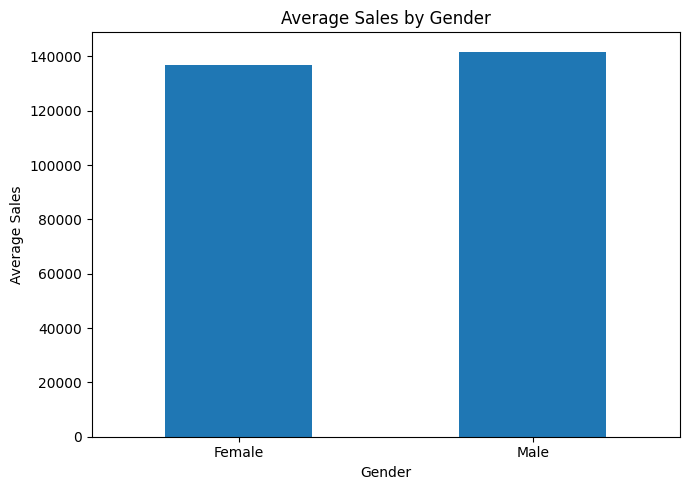

In [12]:

# Average sales comparison

gender_avg = df.groupby("Gender")["Total_Sales"].mean()

plt.figure(figsize=(7,5))

gender_avg.plot(kind="bar")

plt.title("Average Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:

# Save hypothesis testing results

results = pd.DataFrame({
    "Metric": [
        "Male Average Sales",
        "Female Average Sales",
        "T-statistic",
        "P-value",
        "Mean Difference",
        "95% CI Lower",
        "95% CI Upper"
    ],
    "Value": [
        male_sales.mean(),
        female_sales.mean(),
        t_stat,
        p_value,
        mean_diff,
        lower,
        upper
    ]
})

results.to_csv("Hypothesis_Testing_Results.csv", index=False)

print("Results saved successfully!")


Results saved successfully!
